# **AE Complex 3: autoencoder grande en escala de grises con latente de 512 dimensiones**

## **0. Introducción y objetivo**

En `AE_complex2_VGG` cerramos la serie con un FID de reconstrucción de `61.17` y una conclusión clara: ni la dimensión del latente, ni la profundidad de la red, ni la pérdida resuelven por completo la pérdida de detalle a `64x64`. En la sección 11 de ese notebook propusimos como mejora un **autoencoder mayor con latente de `512` dimensiones**, con más capacidad, **dos convoluciones por resolución** y **entrada de un único canal (escala de grises)**. Este notebook lleva a cabo esa propuesta.

A diferencia de los anteriores, **no es una variante de una sola variable**. Cambiamos tres cosas a la vez, tal y como se propuso: la dimensión latente (`256` → `512`), la capacidad de la red (dos convoluciones por resolución y hasta `512` filtros) y la entrada (RGB → luminancia). Para poder interpretar el resultado hemos mantenido fijo todo lo demás con respecto a `AE_complex2_VGG`: mismas particiones, misma semilla, misma pérdida (`L1 + (1 - SSIM)` más pérdida VGG), mismo Cosine Decay y `30` épocas. Además, en la sección 7 reevaluamos el modelo de `AE_complex2_VGG` **en gris** para tener una referencia de FID comparable (el FID en gris no se puede comparar directamente con el de RGB).

Recordamos que un **autoencoder** está formado por un **encoder**, que comprime cada imagen en un vector latente, y un **decoder**, que intenta recuperarla. El *morphing* se hace interpolando entre vectores latentes y decodificando los puntos intermedios, no mezclando píxeles directamente. Como consecuencia de trabajar en gris, el morphing del autoencoder sale en blanco y negro; en la sección 8 incluimos una variante opcional que recupera el color interpolando la crominancia.

Igual que en los notebooks anteriores, trabajamos de forma **determinista en la medida permitida por el entorno**: fijamos las semillas, usamos las particiones guardadas y seleccionamos siempre los mismos ejemplos. El modelo ya está entrenado y sus checkpoints están en `autoencoders/checkpoints/`, por lo que `TRAIN_MODEL` queda a `False` y el notebook carga los modelos y el historial ya calculados (para volver a entrenar, ponerlo a `True`: son unas `2 h 15 min` en la GPU de 4 GB).

El recorrido será: cargar los datos (y pasarlos a gris), definir la arquitectura, justificar la pérdida, entrenar o cargar el modelo, evaluar reconstrucciones en `test`, medir la calidad con FID frente a una referencia en gris y terminar generando una secuencia y un GIF de morphing.

---

## **1. Configuración e imports**

Importamos las bibliotecas de visualización, tratamiento de imágenes, TensorFlow y TorchMetrics. Las rutas se resuelven desde `autoencoders/`, donde está este notebook. Conservamos `attrs.npy` para análisis posteriores, aunque el entrenamiento utiliza las imágenes y sus identificadores.

Los parámetros que cambian respecto a `AE_complex2_VGG` son `CHANNELS = 1` (antes `3`) y `LATENT_DIM = 512` (antes `256`). `BATCH_SIZE` (el lote efectivo de `128`), `EPOCHS` y `SEED` no cambian, pero el lote se procesa en `4` micro-lotes de `32` con **acumulación de gradientes** (`ACCUMULATION_STEPS = 4`, `MICRO_BATCH_SIZE = 32`) para que el entrenamiento quepa en la memoria de la GPU; se explica en la nota técnica de la sección 4. Los checkpoints usan el nombre `ae_complex3_gray512` para no sobrescribir los resultados de los modelos anteriores.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from PIL import Image
from IPython.display import Image as IPyImage, display

I0000 00:00:1793903122.403671    7571 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793903122.809417    7571 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793903124.690464    7571 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
SEED = 1234
IMG_SIZE = 64
# Entrada de un único canal (luminancia) y latente ampliado a 512.
CHANNELS = 1
LATENT_DIM = 512
# Lote efectivo de la serie (128). No cabe de una vez en la GPU de 4 GB: lo procesamos en micro-lotes y
# acumulamos sus gradientes antes de actualizar los pesos (ver la nota técnica de la sección 4).
BATCH_SIZE = 128
ACCUMULATION_STEPS = 4
assert BATCH_SIZE % ACCUMULATION_STEPS == 0
MICRO_BATCH_SIZE = BATCH_SIZE // ACCUMULATION_STEPS
EPOCHS = 30

# Este modelo aún no tiene checkpoints: la primera ejecución entrena. Después, cambiar a False.
TRAIN_MODEL = False
NOTEBOOK_NAME = "ae_complex3_gray512"

PROCESSED_DIR = Path("../data/processed")

# Verificar que están los 9 archivos requeridos
_required_data_files = tuple(
    Path(split) / filename
    for split in ("train", "val", "test")
    for filename in ("x.npy", "attrs.npy", "ids.npy")
)
if not all((PROCESSED_DIR / relative_path).is_file() for relative_path in _required_data_files):
    raise FileNotFoundError(f"Faltan algunos archivos en {PROCESSED_DIR.resolve()}")

CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

AE_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}.keras"
ENCODER_PATH = CHECKPOINT_DIR / f"encoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
DECODER_PATH = CHECKPOINT_DIR / f"decoder_{NOTEBOOK_NAME.replace('ae_', '')}.keras"
HISTORY_PATH = CHECKPOINT_DIR / f"{NOTEBOOK_NAME}_history.json"

np.random.seed(SEED)
tf.random.set_seed(SEED)
print(f"Datos localizados correctamente en: {PROCESSED_DIR.resolve()}")

Datos localizados correctamente en: /home/sanru/Escritorio/7_cuatri/PCD/project/morphing/data/processed


In [3]:
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    # Por defecto TensorFlow reserva casi toda la VRAM. Pedimos memoria solo según la necesite para dejar
    # espacio a PyTorch, que calcula el FID (TorchMetrics) en la misma GPU. Debe ejecutarse antes de usarla.
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(f"No se pudo activar el crecimiento de memoria (reinicia el kernel): {error}")
    print(f"GPU detectada: {gpus}")
else:
    print("Corriendo en CPU.")

GPU detectada: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

## **2. Carga de `train`, `val` y `test` en escala de grises**

No volvemos a crear un *split*: respetamos exactamente las particiones guardadas en `data/processed`, de modo que la comparación con la serie anterior sea justa. Las imágenes están guardadas en RGB (`uint8 [0, 255]`), así que las convertimos a `float32 [0, 1]` y calculamos la **luminancia** con los coeficientes ITU-R BT.601, $Y = 0.299\,R + 0.587\,G + 0.114\,B$ (los mismos que usa `tf.image.rgb_to_grayscale`). El resultado tiene forma `(N, 64, 64, 1)`. La salida del decoder usa una sigmoide, y el autoencoder aprende la identidad, por lo que la entrada y el objetivo de cada ejemplo son la misma imagen.

La conversión se hace por bloques para no duplicar en memoria el conjunto RGB completo en `float32`.

In [4]:
# Coeficientes de luminancia ITU-R BT.601 (R, G, B).
RGB_TO_GRAY = np.array([0.299, 0.587, 0.114], dtype="float32")


def rgb_to_gray(images):
    # images: (..., 3) en [0, 1] -> (..., 1). Se hace por bloques para ahorrar memoria.
    images = np.asarray(images, dtype="float32")
    chunks = [images[start:start + 10000] @ RGB_TO_GRAY for start in range(0, len(images), 10000)]
    return np.concatenate(chunks, axis=0)[..., np.newaxis]


def load_split(name):
    split_dir = PROCESSED_DIR / name
    x = np.load(split_dir / "x.npy", allow_pickle=False)
    attrs = np.load(split_dir / "attrs.npy", allow_pickle=False)
    ids = np.load(split_dir / "ids.npy", allow_pickle=True)
    if x.ndim != 4 or x.shape[1:] != (IMG_SIZE, IMG_SIZE, 3):
        raise ValueError(f"{name}/x.npy tiene forma {x.shape}; se esperaba (N, 64, 64, 3)")
    if attrs.shape[0] != x.shape[0] or ids.shape[0] != x.shape[0]:
        raise ValueError(f"Los archivos de {name} no tienen el mismo número de ejemplos")
    # Normalizamos a [0, 1] y pasamos a luminancia para que coincida con la salida sigmoide del decoder.
    x_gray = np.concatenate(
        [rgb_to_gray(x[start:start + 10000].astype("float32") / 255.0) for start in range(0, len(x), 10000)],
        axis=0,
    )
    return x_gray, attrs, ids

x_train, attrs_train, ids_train = load_split("train")
x_val, attrs_val, ids_val = load_split("val")
x_test, attrs_test, ids_test = load_split("test")

print(f"train: {x_train.shape}, val: {x_val.shape}, test: {x_test.shape}")
print(f"Rango train: [{x_train.min():.3f}, {x_train.max():.3f}]")

train: (60000, 64, 64, 1), val: (5000, 64, 64, 1), test: (10000, 64, 64, 1)
Rango train: [0.000, 1.000]


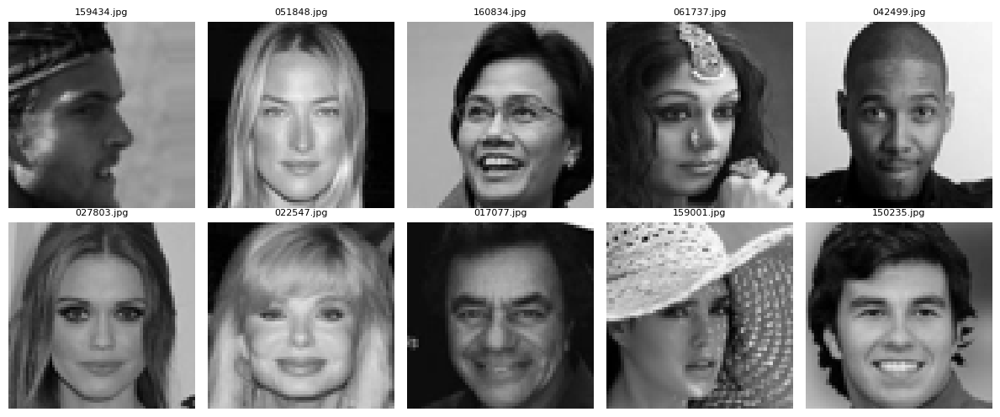

In [5]:
def show_images(images, titles=None, cols=5, figsize=(12, 8)):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, image, index in zip(axes.flat, images, range(len(images))):
        # Las imágenes de un canal se muestran con mapa de grises.
        image = np.clip(np.squeeze(image), 0, 1)
        ax.imshow(image, cmap="gray" if image.ndim == 2 else None, vmin=0, vmax=1)
        ax.axis("off")
        if titles is not None:
            ax.set_title(str(titles[index]), fontsize=8)
    for ax in axes.flat[len(images):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

sample_rng = np.random.default_rng(SEED)
sample_indices = sample_rng.choice(len(x_train), size=10, replace=False)
show_images(x_train[sample_indices], ids_train[sample_indices], cols=5, figsize=(12, 5))

---

## **3. Encoder, decoder y autoencoder**

Seguimos la arquitectura propuesta en `AE_complex2_VGG`. El **encoder** comprime cada cara en escala de grises de `64x64x1` en un vector latente de `512` valores y el **decoder** devuelve un canal en `[0, 1]`.

### **Qué cambia respecto a `AE_complex1_latent`**

- **Dos convoluciones por resolución.** En cada etapa, una convolución `4x4` con `stride=2` reduce la resolución (sigue siendo la convolución la que reduce, sin `MaxPooling`) y una convolución `3x3` con `stride=1` mezcla la información a esa resolución. En el decoder, tras el sobremuestreo bilineal, hay dos convoluciones `3x3`.
- **Más filtros.** El encoder pasa de `(32, 64, 128, 256)` a `(64, 128, 256, 512)` y el mapa `4x4` del cuello de botella tiene `512` canales en lugar de `256`.
- **Latente de `512` dimensiones**, el doble que en `AE_complex1_latent`. Con una entrada de un canal la compresión pasa de `12288 / 256 = 48` a `4096 / 512 = 8` valores de entrada por coordenada, es decir, un cuello de botella **mucho menos estricto**.
- **Un único canal de entrada y de salida.** Solo cambian las dimensiones de la primera convolución del encoder y de la última del decoder.

### **Hipótesis del experimento**

Con tres cambios a la vez esperamos una mejora en la reconstrucción, y lo esperamos por tres motivos distintos: el latente ya no limita tanto (la mejora de `128` a `256` fue notable), la capacidad adicional sí debería aprovecharse ahora que el cuello de botella es más ancho (en `AE_complex2` los bloques residuales no ayudaron porque el cuello de botella seguía siendo el límite), y la tarea en gris es más sencilla porque solo hay que codificar la luminancia. A cambio, el modelo es **bastante más grande**, y como tres cosas cambian a la vez no podremos atribuir la mejora a una de ellas en concreto. Lo que sí podremos decir es si el conjunto compensa su coste.

No incluimos bloques residuales (no aportaron nada en `AE_complex2`) y mantenemos las convoluciones sin sesgo seguidas de `BatchNormalization` y `LeakyReLU`.

In [6]:
# Bloque convolucional común: convolución, normalización y activación.
def conv_block(x, filters, kernel_size=3, strides=1):
    x = layers.Conv2D(filters, kernel_size, strides=strides, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.LeakyReLU(negative_slope=0.2)(x)


# Por resolución: una conv 4x4 con stride 2 (reduce) y una conv 3x3 (mezcla la información).
encoder_inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="encoder_input")
x = encoder_inputs
for filters in (64, 128, 256, 512):
    x = conv_block(x, filters, kernel_size=4, strides=2)
    x = conv_block(x, filters)
x = layers.Flatten()(x)
z = layers.Dense(
    LATENT_DIM,
    kernel_regularizer=keras.regularizers.l2(1e-5),
    name="latent_vector",
)(x)
encoder_ae = keras.Model(encoder_inputs, z, name="encoder_ae")
encoder_ae.summary()

I0000 00:00:1793903136.137592    7571 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2142 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "encoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 256)      │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 256)      │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 512)      │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 4, 4, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 10,089,472 (38.49 MB)

 Trainable params: 10,085,632 (38.47 MB)

 Non-trainable params: 3,840 (15.00 KB)

In [7]:
decoder_inputs = keras.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(4 * 4 * 512, use_bias=False)(decoder_inputs)
x = layers.BatchNormalization()(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)
x = layers.Reshape((4, 4, 512))(x)

# Cada bloque duplica la resolución (4 -> 8 -> 16 -> 32 -> 64) y aplica dos convoluciones 3x3.
for filters in (512, 256, 128, 64):
    x = layers.UpSampling2D(size=(2, 2), interpolation="bilinear")(x)
    x = conv_block(x, filters)
    x = conv_block(x, filters)

decoder_outputs = layers.Conv2D(
    CHANNELS, kernel_size=3, padding="same", activation="sigmoid", name="decoder_output"
)(x)
decoder_ae = keras.Model(decoder_inputs, decoder_outputs, name="decoder_ae")
decoder_ae.summary()

Model: "decoder_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8192)           │     4,194,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 8192)           │        32,768 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 4, 4, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 512)      │     2,359,296 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_10 (LeakyReLU)      │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 16, 16, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 256)    │     1,179,648 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_11 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 256)    │       589,824 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_12 (LeakyReLU)      │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 32, 32, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 32, 32, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 11,276,353 (43.02 MB)

 Trainable params: 11,256,129 (42.94 MB)

 Non-trainable params: 20,224 (79.00 KB)

In [8]:
autoencoder_input = keras.Input(shape=(IMG_SIZE, IMG_SIZE, CHANNELS), name="autoencoder_input")
autoencoder = keras.Model(
    autoencoder_input,
    decoder_ae(encoder_ae(autoencoder_input)),
    name="autoencoder",
)
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_ae (Functional)         │ (None, 512)            │    10,089,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_ae (Functional)         │ (None, 64, 64, 1)      │    11,276,353 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,365,825 (81.50 MB)

 Trainable params: 21,341,761 (81.41 MB)

 Non-trainable params: 24,064 (94.00 KB)

---

## **4. Función de pérdida perceptual y optimización**

Mantenemos exactamente la pérdida de `AE_complex2_VGG`, que fue la que mejor FID consiguió en la serie:

$$L_{total} = 0.5\,L_1 + 0.5\,(1 - SSIM) + \lambda\, L_{VGG}, \qquad \lambda = 10^{-4}$$

donde $L_{VGG}$ es la diferencia $L_1$ entre las activaciones de `block1_conv2` y `block2_conv2` de una VGG16 congelada. Así, la única diferencia con el notebook anterior en cuanto al objetivo es que las imágenes tienen un solo canal.

**Adaptación a un canal.** VGG16 espera tres canales (RGB), así que **replicamos el canal de luminancia tres veces** antes de aplicar `preprocess_input`. Esto no añade parámetros ni información; solo adapta la forma de la entrada a la red. Las activaciones tempranas (bordes y texturas) siguen siendo informativas sobre una imagen en gris, aunque VGG16 se entrenó con color.

Mantenemos también `Cosine Decay` de `1e-3` a `1e-5` a lo largo de las `30` épocas y `EarlyStopping`. Igual que en `AE_complex2_VGG`, el valor de `loss` y `val_loss` incluye el término VGG, por lo que **no es comparable con los de los notebooks sin VGG**; comparamos con el FID.

### **Nota técnica: acumulación de gradientes (`gradient_accumulation_steps`)**

Esta es la **única diferencia de entrenamiento respecto a la serie** y conviene entenderla bien, porque no cambia el modelo ni la pérdida pero sí cómo se calcula cada actualización de los pesos.

**El problema.** Con el lote de la serie (`BATCH_SIZE = 128`), este modelo no cabe en una GPU de `4 GB` (RTX 3050 de portátil). Estimamos lo que hay que guardar en un paso de entrenamiento para la retropropagación (salidas de capa por lote de `128`):

| Componente | Memoria |
| --- | --- |
| Encoder | `0.36 GiB` |
| Decoder (concentra la mayor parte: `512` filtros y dos convoluciones por resolución, con tensores de `256 MiB` en las etapas de `64x64`) | `1.88 GiB` |
| VGG truncada sobre la imagen original y la reconstrucción | `0.82 GiB` |
| Pesos, gradientes y estados de Adam (`21.4 M` de parámetros) | `0.32 GiB` |
| **Total (cota inferior)** | **`3.38 GiB`** |

Es una cota inferior: no cuenta el espacio de trabajo de cuDNN ni de XLA. En la práctica, el primer intento de entrenar así falló: el asignador de memoria de TensorFlow no pudo reservar `1.59 GiB` ni `865 MiB`, y el entrenamiento se quedó bloqueado sin avanzar.

**Por qué no simplemente bajar el `BATCH_SIZE`.** Entrenar con lote `32` daría `4` veces más actualizaciones por época, cada una con un gradiente más ruidoso, y con la misma tasa de aprendizaje que la serie. Sería un experimento distinto y la comparación con los demás notebooks perdería validez.

**La solución.** Procesamos **micro-lotes de `32` imágenes** y dejamos que el optimizador **acumule** los gradientes de `4` micro-lotes consecutivos; solo entonces actualiza los pesos, con la media de esos gradientes (`Adam(gradient_accumulation_steps=4)`). Como la pérdida es una media por imagen, el gradiente medio de `4` micro-lotes de `32` es el mismo que el de un lote de `128`: **el lote efectivo sigue siendo `128`**, igual que la tasa de aprendizaje y el número de actualizaciones por época (`≈ 468.8`). El pico de memoria baja a una cuarta parte de las activaciones (estimación mínima `1.08 GiB` para el micro-lote de `32`).

**Qué hemos verificado.** Con un modelo pequeño en CPU, un paso con un lote de `128` y un paso con `4` micro-lotes de `32` acumulados dan los mismos pesos, con una diferencia máxima de `~1e-10`, tanto con SGD como con Adam. También comprobamos cómo cuenta los pasos el programador de la tasa de aprendizaje (ver el primer punto de abajo). **En la GPU de 4 GB funcionó:** con micro-lotes de `32` el entrenamiento de las `30` épocas se completó sin errores de memoria.

**Precauciones y diferencias que sí existen:**

1. **`DECAY_STEPS` se calcula con micro-pasos.** Keras evalúa el programador de la tasa de aprendizaje con el contador de micro-pasos y no con el de actualizaciones reales. Si se calculara con `BATCH_SIZE`, el `Cosine Decay` terminaría en una cuarta parte del entrenamiento: lo comprobamos, y a mitad del entrenamiento la tasa de aprendizaje valdría `1e-5` en lugar de `5e-4`. Por eso `DECAY_STEPS` usa `MICRO_BATCH_SIZE` (`56250` pasos en lugar de `14070`).
2. **`BatchNormalization` ve `32` imágenes y no `128`.** Calcula sus estadísticas con cada micro-lote, que son algo más ruidosas, y actualiza sus medias móviles `4` veces más a menudo. Es la única diferencia que la acumulación **no elimina**, y puede afectar ligeramente a los resultados.
3. **Las ventanas de acumulación no encajan exactamente con las épocas.** Hay `1875` micro-pasos por época y `1875 = 468 · 4 + 3`, así que los últimos micro-lotes de una época se acumulan con los primeros de la siguiente. Al final del entrenamiento, `2` micro-lotes no llegan a aplicarse. El efecto es despreciable, pero no es idéntico a entrenar con lote `128` real (cuyo último lote de cada época tiene `96` imágenes).
4. **Velocidad:** más pasos y más pequeños aprovechan peor la GPU, así que cabe esperar que cada época tarde más que con un lote de `128` si este cupiera. Lo que sí medimos: `≈ 269 s` por época con este montaje (ver 9.3); no tenemos la medida con un lote real de `128`, porque no cabe.
5. **Reproducibilidad:** los resultados no serán idénticos bit a bit a los de un entrenamiento con lote `128` real, aunque estadísticamente son equivalentes salvo por el punto `2`.

Los notebooks anteriores de la serie no necesitan este cambio si se entrenan en una GPU con memoria suficiente.

In [9]:
def ssim_l1_loss(y_true, y_pred):
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    structural_loss = 1.0 - tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=1.0))
    return 0.5 * l1 + 0.5 * structural_loss

LAMBDA = 1e-4
vgg = keras.applications.VGG16(
    include_top=False,
    weights="imagenet",
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
)
vgg.trainable = False
LAYERS = ["block1_conv2", "block2_conv2"]
feat = keras.Model(vgg.input, [vgg.get_layer(name).output for name in LAYERS], name="vgg_features")
feat.trainable = False


def perceptual(y_true, y_pred):
    # VGG exige 3 canales: replicamos la luminancia antes de pasar a la escala 0-255 de VGG.
    preprocess = lambda x: keras.applications.vgg16.preprocess_input(tf.repeat(x, 3, axis=-1) * 255.0)
    true_features = feat(preprocess(y_true), training=False)
    pred_features = feat(preprocess(y_pred), training=False)
    return tf.add_n([
        tf.reduce_mean(tf.abs(true - pred))
        for true, pred in zip(true_features, pred_features)
    ])


def full_loss(y_true, y_pred):
    return ssim_l1_loss(y_true, y_pred) + LAMBDA * perceptual(y_true, y_pred)


INITIAL_LEARNING_RATE = 1e-3
MIN_LEARNING_RATE = 1e-5
# Con acumulación de gradientes, el programador de la tasa de aprendizaje cuenta micro-pasos y no
# actualizaciones. Por eso DECAY_STEPS se calcula con el micro-lote: con BATCH_SIZE quedaría 4 veces
# demasiado corto y la tasa de aprendizaje llegaría a su mínimo a mitad del entrenamiento.
DECAY_STEPS = int(np.ceil(len(x_train) / MICRO_BATCH_SIZE) * EPOCHS)
learning_rate_schedule = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=INITIAL_LEARNING_RATE,
    decay_steps=DECAY_STEPS,
    alpha=MIN_LEARNING_RATE / INITIAL_LEARNING_RATE,
)

autoencoder.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=learning_rate_schedule,
        gradient_accumulation_steps=ACCUMULATION_STEPS,
    ),
    loss=full_loss,
)
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
]

---

## **5. Entrenamiento y guardado**

Con `TRAIN_MODEL = True` entrenamos usando únicamente `train` y validamos con `val` durante un máximo de `30` épocas; `test` queda reservado para la evaluación final. Guardamos el autoencoder, el encoder, el decoder y el historial para poder reproducir el resto del notebook sin volver a entrenar. Con `TRAIN_MODEL = False` cargamos esos artefactos ya calculados.

**Resultado del entrenamiento.** Las `30` épocas se completaron sin que `EarlyStopping` interviniera: la mejor época según `val_loss` es la **última (`30`)**, con `loss = 0.0866` y `val_loss = 0.0821`. La validación seguía bajando al final, pero muy poco (`0.0833 → 0.0823 → 0.0821` en las tres últimas épocas), porque la tasa de aprendizaje de la `CosineDecay` ya había llegado a `~1e-5`. No sabemos cuánto habría mejorado con más épocas, ya que el programa de la tasa de aprendizaje está atado a las `30`. Cada época tardó unos `269 s` (`317 s` la primera, que incluye la compilación XLA), es decir, **unas `2 h 15 min`** en total en la RTX 3050 de portátil. Estos valores de pérdida **no son comparables** con los de los notebooks anteriores: las imágenes son en gris y la pérdida incluye el término VGG.

### **Nota técnica: por qué entregamos los datos por lotes (`BatchSequence`)**

En los notebooks anteriores de la serie entrenamos con `autoencoder.fit(x_train, x_train, batch_size=...)`. **Aquí no lo hacemos así**: es el mismo cambio que se hizo en `VAE_complex1`, donde resolvió un error de memoria, y conviene entenderlo porque no afecta al modelo, solo a la memoria.

**El problema.** Cuando se le pasa a `fit` un array de NumPy, Keras lo incorpora **entero** como una constante de su canal de datos (`tf.data`), y si hay GPU esa constante se copia a la memoria de la GPU de una sola vez. En `VAE_complex1`, con `x_train` en RGB (`60000 × 64 × 64 × 3 × 4 bytes ≈ 2.95 GB`), el entrenamiento fallaba antes de empezar con `InternalError: Failed copying input tensor from CPU to GPU ... Dst tensor is not initialized`, que en la práctica es un *out of memory* de una GPU de `4 GB`.

**Por qué lo aplicamos también aquí.** En escala de grises `x_train` ocupa `60000 × 64 × 64 × 1 × 4 bytes ≈ 1 GB`, una tercera parte, así que esa copia por sí sola probablemente cabría. Pero este autoencoder tiene `≈ 21 M` de parámetros y activaciones grandes (`512` filtros, dos convoluciones por resolución, VGG sobre original y reconstrucción) que comparten la misma GPU, y dejar `1 GB` de datos residente en ella solo resta margen. Preferimos el mismo mecanismo que en el VAE, para que el entrenamiento sea coherente entre notebooks.

**La solución.** Una clase `BatchSequence` (un `keras.utils.PyDataset`) que **mantiene las imágenes en la RAM** y entrega a Keras un micro-lote de `32` imágenes cada vez (ver la nota de acumulación de gradientes en la sección 4), como pareja `(entrada, objetivo)` idéntica. Se usa igual para `val`.

**Qué cambia y qué no:**

- **No cambia** el modelo, la pérdida, el optimizador, el `Cosine Decay`, el tamaño de lote efectivo (`128`) ni las épocas.
- **Barajado:** `fit(x_train)` baraja las imágenes en cada época, y `train` está ordenado por identificador de imagen, así que es importante barajar también la primera época. `BatchSequence(shuffle=True)` baraja al crearse y al final de cada época, con un generador con semilla fija (`SEED`), de modo que el orden es reproducible. **No será exactamente el mismo orden** que con `fit(x_train, x_train)`, por lo que los resultados no son idénticos bit a bit a los de un entrenamiento hecho de la otra forma, aunque estadísticamente son equivalentes. Se trata de la misma fuente de variación que cambiar la semilla.
- **No lo hemos medido** en este notebook: no sabemos cuánta memoria de GPU ahorra aquí en concreto (el entrenamiento sí cabe en la GPU de `4 GB`).

In [10]:
class BatchSequence(keras.utils.PyDataset):
    """Entrega los lotes desde la RAM. Evita que fit(x_train) copie el conjunto entero a la GPU."""

    def __init__(self, images, batch_size, shuffle=False, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.images = images
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.indices = np.arange(len(images))
        # train está ordenado por id: barajamos ya desde la primera época, como hace fit().
        if self.shuffle:
            self.rng.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.images) / self.batch_size))

    def __getitem__(self, index):
        batch_indices = self.indices[index * self.batch_size:(index + 1) * self.batch_size]
        batch = self.images[batch_indices]
        # Un autoencoder aprende la identidad: la entrada y el objetivo son el mismo lote.
        return batch, batch

    def on_epoch_end(self):
        # Y volvemos a barajar al final de cada época, como hace fit() con shuffle=True.
        if self.shuffle:
            self.rng.shuffle(self.indices)


if TRAIN_MODEL:
    train_batches = BatchSequence(x_train, MICRO_BATCH_SIZE, shuffle=True)
    val_batches = BatchSequence(x_val, MICRO_BATCH_SIZE)
    history_ae = autoencoder.fit(
        train_batches,
        epochs=EPOCHS,
        validation_data=val_batches,
        callbacks=callbacks,
    )
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    autoencoder.save(AE_PATH)
    encoder_ae.save(ENCODER_PATH)
    decoder_ae.save(DECODER_PATH)
    HISTORY_PATH.write_text(json.dumps({
        key: [float(value) for value in values]
        for key, values in history_ae.history.items()
    }, indent=2))
else:
    required = [AE_PATH, ENCODER_PATH, DECODER_PATH, HISTORY_PATH]
    missing = [str(path) for path in required if not path.exists()]
    if missing:
        raise FileNotFoundError("Faltan checkpoints para TRAIN_MODEL=False: " + ", ".join(missing))
    autoencoder = keras.models.load_model(AE_PATH, custom_objects={"ssim_l1_loss": ssim_l1_loss, "perceptual": perceptual, "full_loss": full_loss})
    encoder_ae = keras.models.load_model(ENCODER_PATH)
    decoder_ae = keras.models.load_model(DECODER_PATH)
    history_ae = type("History", (), {"history": json.loads(HISTORY_PATH.read_text())})()

In [11]:
val_losses = history_ae.history["val_loss"]
best_index = int(np.argmin(val_losses))

print(f"Mejor época: {best_index + 1}")
print(f"Loss de entrenamiento: {history_ae.history['loss'][best_index]:.6f}")
print(f"Val loss: {val_losses[best_index]:.6f}")

Mejor época: 30
Loss de entrenamiento: 0.086596
Val loss: 0.082112


---

## **6. Reconstrucciones en test**

Comprobamos que el autoencoder conserva la identidad visual de imágenes que no usó para actualizar sus pesos y representamos la evolución de la pérdida (que incluye el término VGG). Una separación creciente entre entrenamiento y validación puede indicar *overfitting*, algo a vigilar especialmente aquí porque el modelo es bastante más grande que los anteriores.

Después calculamos el FID de las reconstrucciones, que es la métrica que usaremos para comparar con la serie.

**Curvas de pérdida.** No hay sobreajuste. Entre las épocas `6` y `23`, la validación queda **por encima** del entrenamiento, con una separación máxima de unas `0.02` (época `12`: `0.1176` frente a `0.1393`), y además con altibajos (`val_loss` sube en las épocas `10-12` y `18`). A partir de la época `24` la separación se cierra y la validación pasa a quedar **por debajo** del entrenamiento (`0.0821` frente a `0.0866` al final). Que la validación sea menor que el entrenamiento es habitual y no indica un fallo: la pérdida de entrenamiento es la media de toda la época, calculada mientras los pesos todavía mejoran y con la normalización por lotes en modo entrenamiento, mientras que la de validación se calcula al final con los pesos ya actualizados. A falta de una comprobación específica, no podemos asegurar cuál de estos efectos pesa más. En todo caso, `train` y `val` terminan juntos, a pesar de que el modelo es unas `5.6` veces mayor que el de `AE_complex1_latent`.

**Reconstrucciones.** Conservan bien la pose, la expresión, la forma del pelo y los accesorios grandes (el sombrero del hombre se reproduce con claridad). Se pierde el detalle fino: los mechones de pelo salen como una masa suave, las texturas y los pendientes (`187705.jpg`, `191426.jpg`) se desdibujan y todos los resultados están algo borrosos. Es el mismo defecto que ya describimos en la serie, y duplicar el latente a `512` no lo elimina.

I0000 00:00:1793903139.617240    8730 service.cc:153] XLA service 0x7e4a4803b7e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793903139.617263    8730 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.25.1)
I0000 00:00:1793903139.639279    8730 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1793903139.758383    8730 cuda_dnn.cc:461] Loaded cuDNN version 92501
W0000 00:00:1793903154.045801    8730 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.09GiB (rounded to 1176011264)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793903154.051

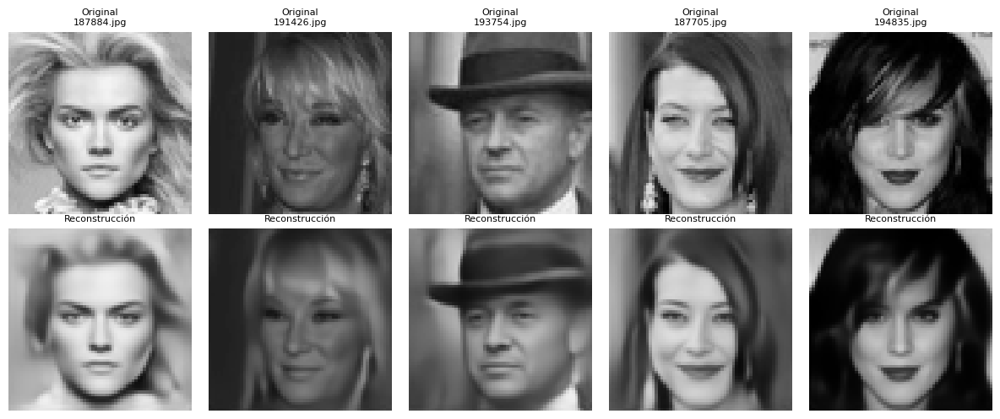

In [12]:
test_indices = sample_rng.choice(len(x_test), size=5, replace=False)
test_reconstructions = autoencoder.predict(x_test[test_indices], verbose=0)
comparison = np.concatenate([x_test[test_indices], test_reconstructions], axis=0)
titles = [f"Original\n{ids_test[i]}" for i in test_indices] + ["Reconstrucción"] * len(test_indices)
show_images(comparison, titles, cols=5, figsize=(12, 5))

Mejor época según val_loss: 30


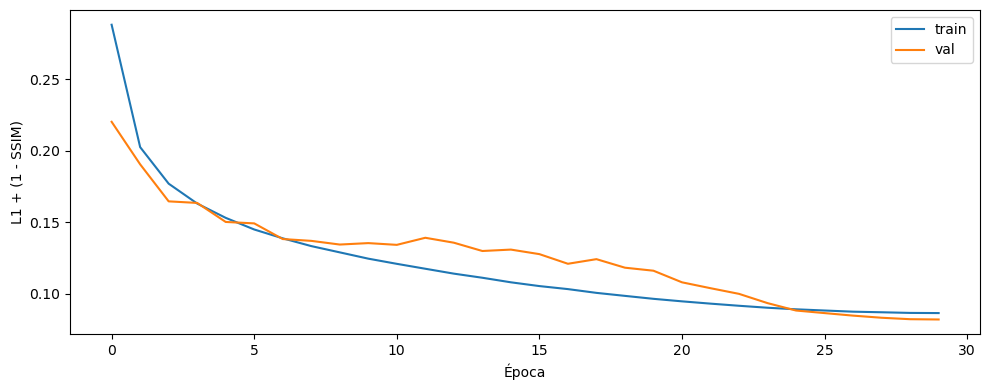

In [13]:
if hasattr(history_ae, "history") and "val_loss" in history_ae.history:
    best_epoch = int(np.argmin(history_ae.history["val_loss"])) + 1
    print(f"Mejor época según val_loss: {best_epoch}")
    plt.figure(figsize=(10, 4))
    plt.plot(history_ae.history["loss"], label="train")
    plt.plot(history_ae.history["val_loss"], label="val")
    plt.xlabel("Época")
    plt.ylabel("L1 + (1 - SSIM)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [14]:
# FID de reconstrucciones y preparación para el FID del morphing
# El FID compara distribuciones de imágenes; por eso se usa un conjunto de test.
FID_DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FID_REAL_SAMPLES = min(1000, len(x_test))
FID_BATCH_SIZE = 32


def prepare_images_for_fid(images):
    images = np.asarray(images)
    if images.ndim == 3:
        images = images[..., np.newaxis]
    if images.ndim != 4 or images.shape[-1] not in (1, 3):
        raise ValueError(f"Se esperaban imágenes con forma (N, H, W, 1|3); recibidas {images.shape}")
    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)
    if images.shape[-1] == 1:
        images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(np.ascontiguousarray(images))


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    generated_images = prepare_images_for_fid(generated_images)
    real_images = prepare_images_for_fid(real_images)
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(FID_DEVICE)
    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(FID_DEVICE), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(FID_DEVICE), real=False)
    # El cálculo final (raíz de la matriz de covarianzas) se hace en la CPU: si TensorFlow y PyTorch comparten
    # proceso, cuSOLVER de PyTorch puede fallar con CUSOLVER_STATUS_INTERNAL_ERROR. Las características de
    # Inception ya se han calculado en la GPU, así que esto solo mueve unas pocas matrices.
    fid = fid.cpu()
    return float(fid.compute().item())

---

## **7. FID y morphing mediante interpolación en el espacio latente**

El **Fréchet Inception Distance (FID)** compara dos distribuciones de imágenes a partir de características extraídas por una red Inception; un FID más bajo indica que las imágenes generadas se parecen más, en distribución, a las reales. Usamos el mismo protocolo que en toda la serie: `1000` reconstrucciones de `test` frente a `1000` imágenes reales distintas de `test`.

**Cómo hacemos comparable el FID en gris.** TorchMetrics espera tres canales, así que `prepare_images_for_fid` replica el canal de luminancia. La referencia real es también la luminancia de las imágenes de `test`, de modo que comparamos **gris con gris**. Sin embargo, un FID en gris **no es comparable directamente** con los `61.17` o `63.65` de la serie RGB, porque la red Inception se entrenó con color y las distribuciones comparadas son distintas. Por eso, además del FID de este modelo, calculamos el de las reconstrucciones del modelo de `AE_complex2_VGG` **convertidas a gris** y comparadas con la misma referencia en gris. Esa es la comparación válida para ver si la combinación latente `512` + más capacidad + gris mejora algo.

**Resultado.** Con el protocolo de siempre (`1000` reconstrucciones frente a `1000` imágenes distintas de `test`, ambas en gris):

| Modelo | FID de reconstrucción (gris) |
| --- | --- |
| `AE_complex2_VGG` (reevaluado en gris) | `57.21` |
| `AE_complex3` | `55.72` |

`AE_complex3` mejora en **`1.49` puntos** (`≈ 2.6 %`). Es una mejora pequeña, y no podemos darla por segura: con solo `1000` imágenes, diferencias de menos de un punto ya están en el orden del ruido de la métrica, y no hemos medido la variabilidad de este FID (por ejemplo, repitiendo con otras muestras de `test` o con otras semillas de entrenamiento), así que `1.49` queda cerca de ese orden de magnitud y no es concluyente. Además, el FID de `AE_complex2_VGG` baja de `61.17` (RGB) a `57.21` (gris) sin cambiar nada del modelo, lo que confirma que **los FID en gris y en color no se pueden comparar entre sí**: solo es válida la comparación gris con gris de la tabla.

In [15]:
fid_reconstruction_images = x_test[:FID_REAL_SAMPLES]
fid_reconstruction_reference = x_test[FID_REAL_SAMPLES:2 * FID_REAL_SAMPLES]
reconstructed_test_images = autoencoder.predict(
    fid_reconstruction_images,
    batch_size=FID_BATCH_SIZE,
    verbose=0,
)
reconstruction_fid = calculate_fid(
    reconstructed_test_images,
    fid_reconstruction_reference,
)
print(f"FID de reconstrucciones ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

W0000 00:00:1793903168.564066    8731 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.52GiB (rounded to 1636073984)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793903168.564158    8731 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1793903168.564163    8731 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 125, Chunks in use: 125. 31.2KiB allocated for chunks. 31.2KiB in use in bin. 18.7KiB client-requested in use in bin.
I0000 00:00:1793903168.564173    8731 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 75, Chunks in use: 74. 39.0KiB allocated for chunks. 38.2KiB in use in bin. 37.0KiB client-requested in use in bin.
I0000 00:00:1793903168.564180    8731 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 76, Chunks in use: 76. 78.0KiB allocat

FID de reconstrucciones (1000 imágenes): 55.7276


In [16]:
# Referencia comparable: reconstrucciones RGB del mejor modelo anterior (AE_complex2_VGG), pasadas a gris.
baseline_dir = next(
    (
        directory
        for directory in (CHECKPOINT_DIR,)
        if (directory / "encoder_complex2_vgg256.keras").is_file()
        and (directory / "decoder_complex2_vgg256.keras").is_file()
    ),
    None,
)
if baseline_dir is None:
    print("No se encuentran encoder/decoder de AE_complex2_VGG; se omite la referencia en gris.")
else:
    encoder_baseline = keras.models.load_model(baseline_dir / "encoder_complex2_vgg256.keras")
    decoder_baseline = keras.models.load_model(baseline_dir / "decoder_complex2_vgg256.keras")
    x_test_rgb = np.load(PROCESSED_DIR / "test" / "x.npy", mmap_mode="r")[:FID_REAL_SAMPLES].astype("float32") / 255.0
    baseline_rgb = decoder_baseline.predict(
        encoder_baseline.predict(x_test_rgb, batch_size=FID_BATCH_SIZE, verbose=0),
        batch_size=FID_BATCH_SIZE,
        verbose=0,
    )
    baseline_gray_fid = calculate_fid(rgb_to_gray(baseline_rgb), fid_reconstruction_reference)
    print(f"FID en gris de AE_complex2_VGG ({FID_REAL_SAMPLES} imágenes): {baseline_gray_fid:.4f}")
    print(f"FID en gris de AE_complex3      ({FID_REAL_SAMPLES} imágenes): {reconstruction_fid:.4f}")

FID en gris de AE_complex2_VGG (1000 imágenes): 57.2292
FID en gris de AE_complex3      (1000 imágenes): 55.7276


W0000 00:00:1793903316.730649    8731 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.10GiB (rounded to 1185677824)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793903316.730749    8731 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1793903316.730754    8731 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 162, Chunks in use: 162. 40.5KiB allocated for chunks. 40.5KiB in use in bin. 22.0KiB client-requested in use in bin.
I0000 00:00:1793903316.730763    8731 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 83, Chunks in use: 82. 43.0KiB allocated for chunks. 42.5KiB in use in bin. 41.0KiB client-requested in use in bin.
I0000 00:00:1793903316.730769    8731 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 85, Chunks in use: 85. 87.5KiB allocat

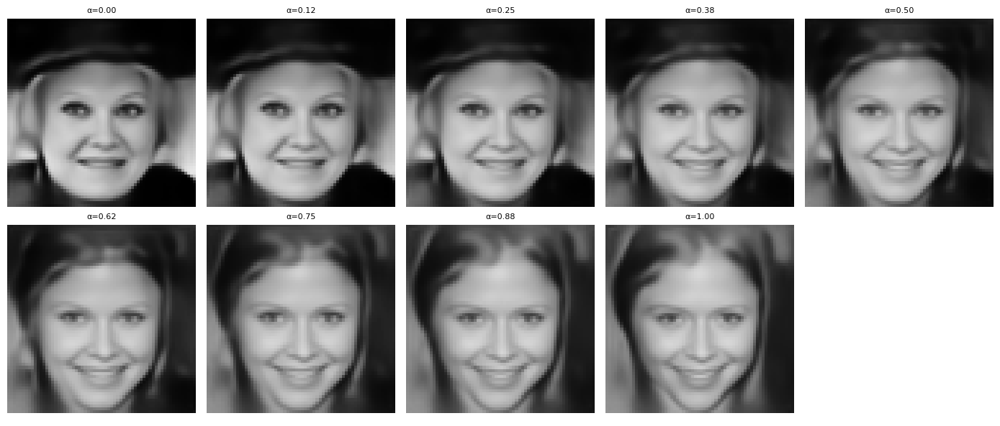

A: 182638.jpg | B: 182640.jpg


In [17]:
def morph_images(image_a, image_b, steps=9):
    if image_a.shape != image_b.shape:
        raise ValueError(f"Las imágenes deben tener la misma forma; recibidas {image_a.shape} y {image_b.shape}")
    z_a = encoder_ae.predict(image_a[None, ...], verbose=0)[0]
    z_b = encoder_ae.predict(image_b[None, ...], verbose=0)[0]
    alphas = np.linspace(0.0, 1.0, steps, dtype=np.float32)
    latent_path = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b
    return alphas, decoder_ae.predict(latent_path, verbose=0)

morph_a_index, morph_b_index = 0, 1
alphas, morph_sequence = morph_images(x_test[morph_a_index], x_test[morph_b_index], steps=9)
show_images(
    morph_sequence,
    [f"α={alpha:.2f}" for alpha in alphas],
    cols=5,
    figsize=(14, 6),
)
print(f"A: {ids_test[morph_a_index]} | B: {ids_test[morph_b_index]}")

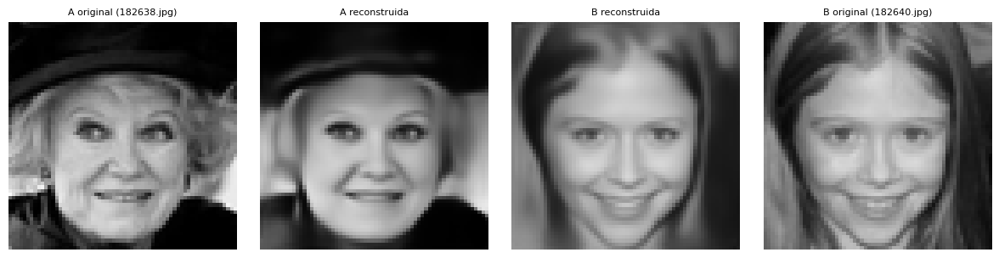

In [18]:
# Comparación de extremos: original frente a reconstrucción usada en la interpolación.
endpoints = np.stack([
    x_test[morph_a_index], morph_sequence[0],
    morph_sequence[-1], x_test[morph_b_index],
])
show_images(
    endpoints,
    [f"A original ({ids_test[morph_a_index]})", "A reconstruida", "B reconstruida", f"B original ({ids_test[morph_b_index]})"],
    cols=4,
    figsize=(12, 3),
)

---

## **8. Secuencia visual y GIF del morphing**

Repetimos la interpolación con muchos valores de $\alpha$ y guardamos los fotogramas como un GIF. La animación nos permite evaluar visualmente si los rasgos cambian de manera gradual, sin saltos ni *ghosting*, complementando la evaluación numérica del FID. Como el modelo trabaja en gris, el GIF principal es en blanco y negro.

### **8.1 Variante opcional: recuperar el color**

Siguiendo lo discutido en la sección 9.4 de `AE_complex2`, generamos también una versión en color. El autoencoder produce la **luminancia** $Y_\alpha$ de cada fotograma; el color lo tomamos de las dos imágenes originales pasando a YCbCr e **interpolando linealmente la crominancia** $(C_b, C_r)$:

$$C_\alpha = (1-\alpha)\,C_A + \alpha\,C_B$$

Esta mezcla se hace en el espacio de píxeles, que es justo el tipo de mezcla que queremos evitar para la estructura de la cara. Aun así, la crominancia es de baja frecuencia (apenas contiene bordes), por lo que el *ghosting* debería ser poco visible. Este GIF **no se evalúa con FID**; solo sirve para comprobar visualmente el resultado.

In [19]:
GIF_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_ae3_gray512_morphing.gif"
N_FRAMES = 80
FRAME_MS = 50

z_a = encoder_ae.predict(
    x_test[morph_a_index][None, ...],
    verbose=0,
)[0]
z_b = encoder_ae.predict(
    x_test[morph_b_index][None, ...],
    verbose=0,
)[0]

alphas = np.linspace(0.0, 1.0, N_FRAMES, dtype=np.float32)
z_frames = (1.0 - alphas[:, None]) * z_a + alphas[:, None] * z_b

decoded = decoder_ae.predict(z_frames, verbose=0)

W0000 00:00:1793903363.425723    8730 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.13GiB (rounded to 1212154368)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1793903363.425822    8730 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1793903363.425828    8730 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 166, Chunks in use: 166. 41.5KiB allocated for chunks. 41.5KiB in use in bin. 22.0KiB client-requested in use in bin.
I0000 00:00:1793903363.425836    8730 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 82, Chunks in use: 82. 42.5KiB allocated for chunks. 42.5KiB in use in bin. 41.0KiB client-requested in use in bin.
I0000 00:00:1793903363.425843    8730 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 85, Chunks in use: 85. 87.5KiB allocat

GIF guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_ae3_gray512_morphing.gif' | 80 fotogramas


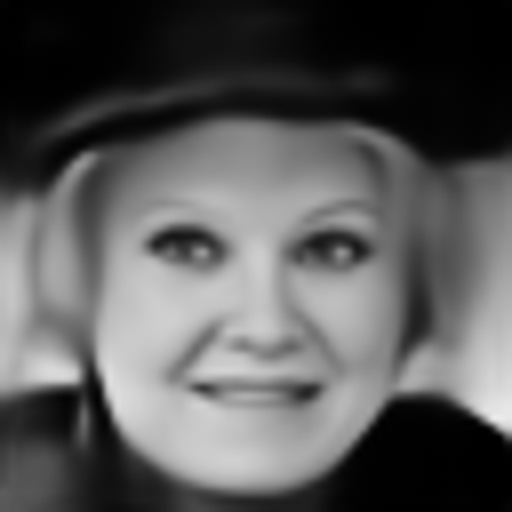

In [20]:
# Las imágenes de un canal se guardan como (H, W); Pillow las interpreta como escala de grises.
frames = [
    Image.fromarray((np.clip(image[..., 0], 0, 1) * 255).astype(np.uint8))
    .resize((512, 512), Image.Resampling.BICUBIC)
    for image in decoded
]

gif_path = Path(GIF_PATH).resolve()
gif_path.parent.mkdir(parents=True, exist_ok=True)
if not frames:
    raise RuntimeError("No se generaron fotogramas para el GIF")

frames[0].save(
    gif_path,
    save_all=True,
    append_images=frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF guardado en '{gif_path}' | {len(frames)} fotogramas")
display(IPyImage(filename=str(gif_path)))

GIF en color guardado en '/home/sanru/Escritorio/7_cuatri/PCD/project/morphing/gif/fusion_ae3_gray512_color_morphing.gif' | 80 fotogramas


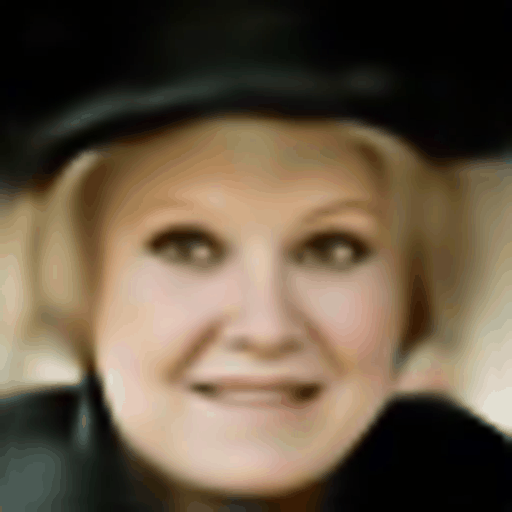

In [21]:
# Variante en color: luminancia del autoencoder + crominancia (Cb, Cr) interpolada linealmente.
def rgb_to_ycbcr(rgb):
    y = rgb @ RGB_TO_GRAY
    return y, (rgb[..., 2] - y) * 0.564, (rgb[..., 0] - y) * 0.713


def ycbcr_to_rgb(y, cb, cr):
    r = y + cr / 0.713
    b = y + cb / 0.564
    g = (y - 0.299 * r - 0.114 * b) / 0.587
    return np.clip(np.stack([r, g, b], axis=-1), 0.0, 1.0)


# Solo necesitamos las dos imágenes originales en color del par del morphing.
pair_rgb = np.load(PROCESSED_DIR / "test" / "x.npy", mmap_mode="r")[[morph_a_index, morph_b_index]].astype("float32") / 255.0
_, cb_a, cr_a = rgb_to_ycbcr(pair_rgb[0])
_, cb_b, cr_b = rgb_to_ycbcr(pair_rgb[1])

weights = alphas[:, None, None]
cb_frames = (1.0 - weights) * cb_a + weights * cb_b
cr_frames = (1.0 - weights) * cr_a + weights * cr_b
color_decoded = ycbcr_to_rgb(decoded[..., 0], cb_frames, cr_frames)

GIF_COLOR_PATH = PROCESSED_DIR.parent.parent / "gif" / "fusion_ae3_gray512_color_morphing.gif"
color_frames = [
    Image.fromarray((image * 255).astype(np.uint8)).resize((512, 512), Image.Resampling.BICUBIC)
    for image in color_decoded
]
gif_color_path = Path(GIF_COLOR_PATH).resolve()
color_frames[0].save(
    gif_color_path,
    save_all=True,
    append_images=color_frames[1:],
    duration=FRAME_MS,
    loop=0,
)

print(f"GIF en color guardado en '{gif_color_path}' | {len(color_frames)} fotogramas")
display(IPyImage(filename=str(gif_color_path)))

---

## **9. Decisiones de diseño, resultados y siguiente paso**

### **9.1 Decisiones de diseño**

- **Tres cambios a la vez, como se propuso:** latente de `512`, más capacidad y entrada en gris. Es un experimento de «paquete» y no una ablación; lo asumimos porque el objetivo era comprobar si la dirección «más grande y más sencilla» merecía la pena. Como contrapartida, no podemos repartir el mérito entre los tres cambios.

- **Dos convoluciones por resolución, sin bloques residuales:** una `4x4` con `stride=2` que reduce y una `3x3` que mezcla la información. Con un cuello de botella más ancho esperamos que la capacidad adicional sí se aproveche, a diferencia de `AE_complex2`.

- **Misma pérdida que `AE_complex2_VGG`:** `L1 + (1 - SSIM)` más pérdida VGG con `λ = 1e-4`, replicando el canal de gris antes de pasar por VGG. Mantenerla permite comparar con el mejor modelo de la serie sin que cambie el objetivo.

- **Referencia en gris para el FID:** el FID en gris y el de RGB no son comparables. Reevaluamos `AE_complex2_VGG` en gris (sección 7) y comparamos solo gris con gris.

- **El color se recupera aparte:** interpolando la crominancia en el espacio de píxeles. Es una solución barata, no forma parte del modelo y su calidad no se mide con el FID.

### **9.2 Resultados**

| Modelo | Entrada | Latente | Pérdida | FID reconstrucción |
| --- | --- | --- | --- | --- |
| `AE_complex1` | RGB | 128 | L1 + SSIM | 72.94 |
| `AE_complex1_latent` | RGB | 256 | L1 + SSIM | 63.65 |
| `AE_complex2` (residual) | RGB | 256 | L1 + SSIM | 64.40 |
| `AE_complex2_VGG` | RGB | 256 | L1 + SSIM + VGG | 61.17 |
| `AE_complex2_VGG` (reevaluado en gris) | Gris | 256 | L1 + SSIM + VGG | 57.21 (gris) |
| `AE_complex3` | Gris | 512 | L1 + SSIM + VGG | 55.72 (gris) |

Los FID en gris solo se comparan entre sí y no con los de RGB. `AE_complex3` obtiene `55.72` frente a los `57.21` de `AE_complex2_VGG` reevaluado en gris: una mejora de `1.49` puntos que, con `1000` imágenes y sin haber medido la variabilidad de la métrica, **no podemos distinguir con seguridad del ruido**.

### **9.3 Coste computacional**

El autoencoder tiene `21.4 M` de parámetros (`10.1 M` el encoder y `11.3 M` el decoder), unas `5.6` veces los `≈ 3.8 M` de `AE_complex1_latent`. La capa `Dense` del cuello de botella pasa de `4·4·256 = 4096` a `4·4·512 = 8192` entradas, y las convoluciones `3x3` con `512` filtros concentran la mayor parte de los parámetros. Es un coste que se paga tanto al entrenar como al generar cada imagen.

El entrenamiento tardó unos `269 s` por época (`≈ 2 h 15 min` las `30` épocas) en la RTX 3050 de portátil, con lotes de `128` procesados como `4` micro-lotes de `32`. Como orientación, en el entrenamiento de `AE_complex2_VGG` figuran unos `203-210 s` por época, pero se hizo con otro equipo y sin acumulación de gradientes, así que **no es una comparación directa** y no podemos atribuir la diferencia solo al tamaño del modelo ni solo a la acumulación. Lo que sí sabemos es que el coste en parámetros (`5.6` veces más que `AE_complex1_latent`) y en tiempo es claramente mayor que la mejora de FID obtenida (`1.49` puntos, dentro del margen de ruido).

### **9.4 Reflexión y siguiente paso**

**Valoración.** El resultado es modesto. El FID mejora `1.49` puntos en gris (no concluyente, ver 9.2) a cambio de un modelo mucho mayor, un entrenamiento más lento y la pérdida del color. Como cambiamos tres cosas a la vez, tampoco podemos decir si el pequeño avance se debe al latente de `512`, a la capacidad extra o al paso a gris. Nuestra conclusión es que **la dirección «más grande y más sencilla» no compensa** por sí sola.

**Morphing.** En el par evaluado (`182638.jpg` → `182640.jpg`) la transición es suave y la cara se mantiene coherente en todos los pasos, sin caras dobles. Se aprecia cierto *ghosting*: el sombrero oscuro del extremo A sigue visible hasta `α ≈ 0.5` y se convierte en pelo entre `α = 0.5` y `α = 0.62`, en lugar de transformarse de forma gradual. Los extremos reconstruidos son más borrosos y menos detallados que los originales (sobre todo el pelo de B). La **variante en color** funciona razonablemente bien: recuperar la crominancia interpolada devuelve un tono de piel y de pelo creíbles, y el pelo pasa gradualmente de rubio a pelirrojo. Es un añadido barato, pero no forma parte del modelo y no se ha medido con FID. Esto es una valoración visual de un único par y no una medida.

Sea cual sea el resultado, este modelo sigue siendo un autoencoder determinista y sigue sin resolver el problema de fondo descrito en la sección 10.2 de `AE_complex2_VGG`: el decoder solo ve los latentes que produce el encoder con `train`, y en el morphing recibe puntos intermedios que nunca ha visto. Aumentar el latente agrava ese efecto (más dimensiones, más zonas vacías). La solución natural es regularizar el espacio latente durante el entrenamiento, que probamos en **`VAE_complex1.ipynb`**, un VAE derivado de `AE_complex2_VGG` (la misma base que este notebook). Allí el VAE consiguió un FID de reconstrucción de `61.57` (prácticamente igual que los `61.17` de `AE_complex2_VGG`), un latente con las `256` dimensiones activas y la capacidad de generar caras desde el prior (FID `87.43`), pero **no mejoró de forma visible el morphing** del par evaluado. Las conclusiones están en ese notebook.